# Performance evaluation for **Xengsort**

## 0. Imports and path assignments

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
import sys
import os
sys.path.append(os.path.abspath(os.path.join("..")))
from helper.visualization import *
from helper.metrics import * 

from warnings import simplefilter
simplefilter("ignore")

In [ ]:
data_dir = Path.cwd().parent / "data"
method = "xengsort_newindex"
fig_dir = Path.cwd() / "figures" / method
fig_dir.mkdir(exist_ok=True, parents=True)

## 1. Load data

In [3]:
df = read_evaluations(data_dir, method)

## Confusion Matrix

In [4]:
df_conf = assign_confusion_matrix(df, method="xengsort")

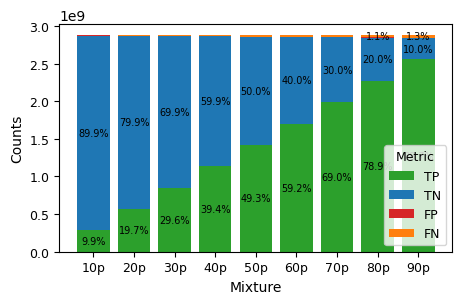

In [5]:
figsize = mm_to_inches((120, 80))
plot_stacked_confusion_bar(
    df_conf,
    save=False,
    figsize= figsize)

## Calculate performance metrics

In [7]:
df_metrics = calculate_metrics(df_conf)

## Save dataframe

In [10]:
df_metrics["Method"] = "Xengsort"

In [25]:
out_dir = Path.cwd() / "results"
out_dir.mkdir(exist_ok=True)

df_metrics.to_csv(out_dir / "xengsort_newindex.csv", index=False)